# TerraMind Latent Velocity Heatmap

This notebook computes a vector-valued Sobel/Scharr latent gradient field over a reconstructed geographic grid of TerraMind embeddings.

In [ ]:
# Notebook environment setup (idempotent)
# If dependencies are not already installed in this uv project, run:
# !uv add torch numpy pandas matplotlib scikit-learn scipy jupyter tqdm
# !uv sync

In [12]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.decomposition import PCA
from scipy.ndimage import convolve, binary_erosion
from tqdm.auto import tqdm
import torch

# Tunable parameters
KERNEL = "sobel"  # 'sobel' | 'scharr'
NORM_PERCENTILE_CLIP = (2, 98)
QUIVER_SUBSAMPLE = 8
PCA_COMPONENTS = 3
GRID_DECIMAL_PRECISION = None  # int or None to infer from data
GRID_MAX_MEMORY_MB = 1024      # guardrail for E(H, W, d) allocation

# Optional region-of-interest constraints (set to float bounds or keep None)
ROI_LAT_MIN = 40
ROI_LAT_MAX = 41
ROI_LON_MIN = 50
ROI_LON_MAX = 51

# Best-square experiment settings
SQUARE_SIZE = 50
SQUARE_STRIDE = 5
ORDERINGS_FOR_SQUARE_SEARCH = ("lat_lon", "lon_lat")

DATA_PATH = Path("data/latents_0_92160.pt")
CACHE_DIR = Path("data/cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=4, suppress=True)

## 1. Load & Inspect Embeddings

Type: dict
Shape: (92160, 3)
dtypes:
lat       float32
lon       float32
latent     object
dtype: object
Sample rows:
         lat         lon                                             latent
0  38.566589  111.513878  [-0.299674, 0.40595922, -0.3495546, -0.4304964...
1  69.062706  -91.597633  [-0.29354703, 0.06753131, -0.6641417, 0.611838...
2  11.417163  104.877945  [-0.26247153, 0.09449736, -0.26273918, -0.1145...
Embedding dimensionality d: 192
NaN counts:
lat NaNs: 0
lon NaNs: 0
latent NaNs: 0


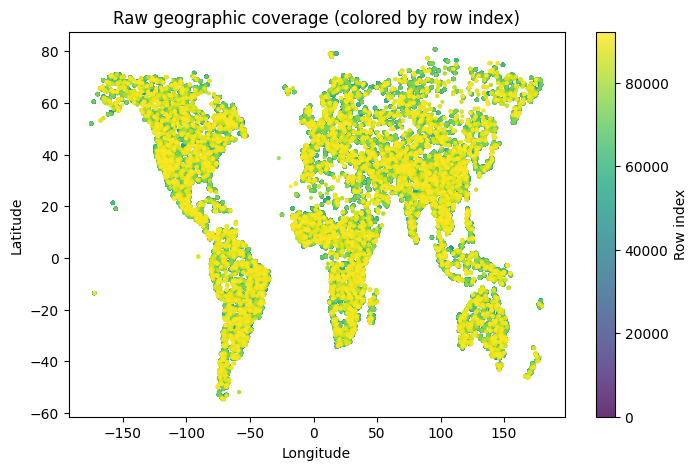

In [4]:
# TODO: add support for multiple shard files (latents_0_*.pt)

obj = torch.load(DATA_PATH, map_location="cpu", weights_only=False)

if isinstance(obj, pd.DataFrame):
    df = obj.copy()
elif isinstance(obj, dict) and {"latents", "meta"}.issubset(obj.keys()):
    latents = obj["latents"]
    meta = obj["meta"]
    if isinstance(latents, torch.Tensor):
        latents = latents.detach().cpu().numpy()
    else:
        latents = np.asarray(latents)
    if isinstance(meta, torch.Tensor):
        meta = meta.detach().cpu().numpy()
    else:
        meta = np.asarray(meta)
    if meta.ndim != 2 or meta.shape[1] < 2:
        raise ValueError(f"Expected meta with at least 2 columns (lat, lon), got shape {meta.shape}")
    if latents.shape[0] != meta.shape[0]:
        raise ValueError(f"latents/meta row mismatch: {latents.shape[0]} vs {meta.shape[0]}")

    df = pd.DataFrame(
        {
            "lat": meta[:, 0],
            "lon": meta[:, 1],
            "latent": [latents[i] for i in range(latents.shape[0])],
        }
    )
elif isinstance(obj, dict) and {"lat", "lon", "latent"}.issubset(obj.keys()):
    df = pd.DataFrame(obj)
elif isinstance(obj, list):
    df = pd.DataFrame(obj)
else:
    raise TypeError(f"Unsupported payload type from torch.load: {type(obj)}")

required_cols = {"lat", "lon", "latent"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Ensure numeric lat/lon and array-like latent vectors
df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["lon"] = pd.to_numeric(df["lon"], errors="coerce")

def to_numpy_vec(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

df["latent"] = df["latent"].apply(to_numpy_vec)

# Determine embedding dimensionality
first_valid_idx = next((i for i, v in enumerate(df["latent"].values) if np.asarray(v).size > 0), None)
if first_valid_idx is None:
    raise ValueError("No non-empty latent vectors found")

d = int(np.asarray(df["latent"].iloc[first_valid_idx]).reshape(-1).shape[0])

def normalize_shape(v):
    a = np.asarray(v).reshape(-1)
    if a.shape[0] != d:
        raise ValueError(f"Inconsistent latent dimension. Expected {d}, got {a.shape[0]}")
    return a

df["latent"] = df["latent"].apply(normalize_shape)

latent_stack = np.vstack(df["latent"].values)

print("Type:", type(obj).__name__)
print("Shape:", df.shape)
print("dtypes:")
print(df.dtypes)
print("Sample rows:")
print(df.head(3))
print("Embedding dimensionality d:", d)

print("NaN counts:")
print("lat NaNs:", int(df["lat"].isna().sum()))
print("lon NaNs:", int(df["lon"].isna().sum()))
print("latent NaNs:", int(np.isnan(latent_stack).sum()))

fig, ax = plt.subplots(figsize=(8, 5))
idx = np.arange(len(df))
sc = ax.scatter(df["lon"], df["lat"], c=idx, s=4, cmap="viridis", alpha=0.8)
ax.set_title("Raw geographic coverage (colored by row index)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.colorbar(sc, ax=ax, label="Row index")
plt.show()

## 2. Reconstruct Geographic Grid

Rows after ROI filter: 16 / 92160
   precision   H   W  cells  unique_pairs  occupancy    est_mb
0          0   2   1      2             2   1.000000  0.001465
1          1   2   2      4             4   1.000000  0.002930
2          2   4   4     16            16   1.000000  0.011719
3          3   7   8     56            16   0.285714  0.041016
4          4  16  16    256            16   0.062500  0.187500
5          5  16  16    256            16   0.062500  0.187500
6          6  16  16    256            16   0.062500  0.187500
Selected grid decimal precision: 2
Grid shape (H, W, d): (4, 4, 192)
Grid completeness check passed: no missing cells


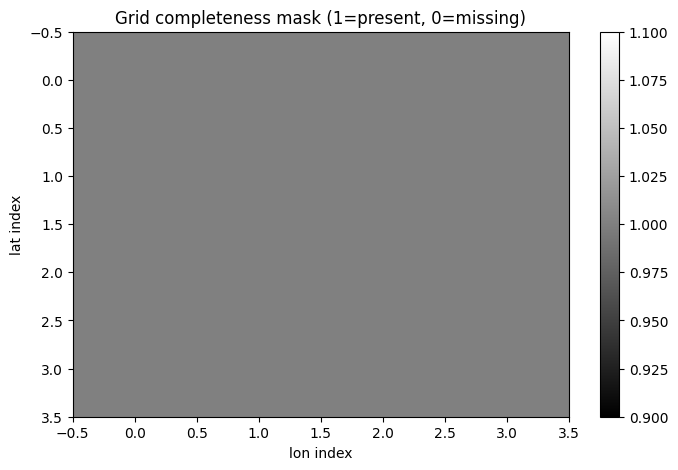

In [13]:
# TODO: handle irregular/non-rectangular grids via interpolation onto regular grid

# Apply optional ROI constraints before grid reconstruction.
df_roi = df.copy()
if ROI_LAT_MIN is not None:
    df_roi = df_roi[df_roi["lat"] >= float(ROI_LAT_MIN)]
if ROI_LAT_MAX is not None:
    df_roi = df_roi[df_roi["lat"] <= float(ROI_LAT_MAX)]
if ROI_LON_MIN is not None:
    df_roi = df_roi[df_roi["lon"] >= float(ROI_LON_MIN)]
if ROI_LON_MAX is not None:
    df_roi = df_roi[df_roi["lon"] <= float(ROI_LON_MAX)]

if len(df_roi) == 0:
    raise ValueError("ROI filter removed all rows. Relax ROI_* bounds.")

print(f"Rows after ROI filter: {len(df_roi)} / {len(df)}")


def precision_candidates(df_in: pd.DataFrame, d: int):
    rows = []
    n = len(df_in)
    for p in range(0, 7):
        lat_r = df_in["lat"].round(p)
        lon_r = df_in["lon"].round(p)
        H = int(lat_r.nunique())
        W = int(lon_r.nunique())
        cells = H * W
        unique_pairs = int(pd.DataFrame({"lat": lat_r, "lon": lon_r}).drop_duplicates().shape[0])
        occupancy = unique_pairs / cells if cells else 0.0
        est_mb = (cells * d * np.dtype(np.float32).itemsize) / (1024**2)
        closeness = abs(np.log((cells + 1e-9) / max(n, 1)))
        rows.append({
            "precision": p,
            "H": H,
            "W": W,
            "cells": cells,
            "unique_pairs": unique_pairs,
            "occupancy": occupancy,
            "est_mb": est_mb,
            "closeness": closeness,
        })
    return pd.DataFrame(rows)

cand = precision_candidates(df_roi, d)
print(cand[["precision", "H", "W", "cells", "unique_pairs", "occupancy", "est_mb"]])

if GRID_DECIMAL_PRECISION is None:
    feasible = cand[cand["est_mb"] <= GRID_MAX_MEMORY_MB].copy()
    if feasible.empty:
        raise MemoryError(
            f"No precision in [0..6] fits memory budget {GRID_MAX_MEMORY_MB} MB. "
            "Set GRID_DECIMAL_PRECISION manually or raise GRID_MAX_MEMORY_MB."
        )
    inferred_precision = int(feasible.sort_values(["closeness", "cells"]).iloc[0]["precision"])
else:
    inferred_precision = int(GRID_DECIMAL_PRECISION)

print("Selected grid decimal precision:", inferred_precision)

df_grid = df_roi.copy()
df_grid["lat_r"] = df_grid["lat"].round(inferred_precision)
df_grid["lon_r"] = df_grid["lon"].round(inferred_precision)

# Multiple points may land in the same rounded cell; aggregate them.
agg = (
    df_grid.groupby(["lat_r", "lon_r"], as_index=False)["latent"]
    .apply(lambda s: np.mean(np.vstack(s.values), axis=0))
)

if len(agg) < len(df_grid):
    warnings.warn(
        f"Rounded grid caused collisions: {len(df_grid) - len(agg)} rows aggregated by mean embedding.",
        stacklevel=2,
    )

lats = np.array(sorted(agg["lat_r"].unique(), reverse=True), dtype=float)  # descending
lons = np.array(sorted(agg["lon_r"].unique()), dtype=float)                 # ascending
H, W = len(lats), len(lons)
print("Grid shape (H, W, d):", (H, W, d))

lat_to_i = {v: i for i, v in enumerate(lats)}
lon_to_j = {v: j for j, v in enumerate(lons)}

E = np.full((H, W, d), np.nan, dtype=np.float32)
for row in agg.itertuples(index=False):
    i = lat_to_i[row.lat_r]
    j = lon_to_j[row.lon_r]
    E[i, j, :] = row.latent

complete_mask = np.all(np.isfinite(E), axis=-1)
missing_cells = int((~complete_mask).sum())
total_cells = int(H * W)

if missing_cells > 0:
    warnings.warn(
        f"Grid is incomplete: {missing_cells}/{total_cells} cells missing. Filled with NaN.",
        stacklevel=2,
    )
else:
    assert complete_mask.all(), "Grid expected complete but found missing cells"
    print("Grid completeness check passed: no missing cells")

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(complete_mask.astype(int), cmap="gray", origin="upper", aspect="auto")
ax.set_title("Grid completeness mask (1=present, 0=missing)")
ax.set_xlabel("lon index")
ax.set_ylabel("lat index")
plt.colorbar(im, ax=ax)
plt.show()

## 2.1 ROI Experiment — Best 50×50 Square by Neighbor Uniformity

In [11]:
# Search for a contiguous square where neighboring embedding distances are most uniform.
# Lower score = more equal neighbor distances.

def evaluate_best_square(E_grid, lat_axis, lon_axis, size, stride, orientation_label):
    H, W, d = E_grid.shape
    if H < size or W < size:
        return None

    best = None
    total_candidates = 0

    for i0 in range(0, H - size + 1, stride):
        for j0 in range(0, W - size + 1, stride):
            total_candidates += 1
            window = E_grid[i0:i0 + size, j0:j0 + size, :]
            valid = np.all(np.isfinite(window), axis=-1)

            # Horizontal neighbor distances
            right_valid = valid[:, :-1] & valid[:, 1:]
            if np.any(right_valid):
                dh = np.linalg.norm(window[:, 1:, :] - window[:, :-1, :], axis=-1)[right_valid]
            else:
                dh = np.array([], dtype=np.float32)

            # Vertical neighbor distances
            down_valid = valid[:-1, :] & valid[1:, :]
            if np.any(down_valid):
                dv = np.linalg.norm(window[1:, :, :] - window[:-1, :, :], axis=-1)[down_valid]
            else:
                dv = np.array([], dtype=np.float32)

            dists = np.concatenate([dh, dv]) if (len(dh) + len(dv)) > 0 else np.array([], dtype=np.float32)
            if len(dists) < max(100, int(0.3 * 2 * size * (size - 1))):
                continue

            mean_dist = float(np.mean(dists))
            if mean_dist <= 1e-12:
                continue

            std_dist = float(np.std(dists))
            cv = std_dist / mean_dist
            coverage = float(valid.mean())

            # Favor uniform distances and high finite coverage.
            score = cv + (1.0 - coverage) * 2.0

            if (best is None) or (score < best["score"]):
                lat_vals = lat_axis[i0:i0 + size]
                lon_vals = lon_axis[j0:j0 + size]
                best = {
                    "orientation": orientation_label,
                    "i0": i0,
                    "j0": j0,
                    "size": size,
                    "score": score,
                    "cv": cv,
                    "coverage": coverage,
                    "mean_dist": mean_dist,
                    "std_dist": std_dist,
                    "lat_min": float(np.min(lat_vals)),
                    "lat_max": float(np.max(lat_vals)),
                    "lon_min": float(np.min(lon_vals)),
                    "lon_max": float(np.max(lon_vals)),
                }

    if best is not None:
        best["candidates_scanned"] = total_candidates
    return best

size = int(SQUARE_SIZE)
stride = max(1, int(SQUARE_STRIDE))
if size < 2:
    raise ValueError("SQUARE_SIZE must be >= 2")

results = []
if "lat_lon" in ORDERINGS_FOR_SQUARE_SEARCH:
    best_lat_lon = evaluate_best_square(E, lats, lons, size=size, stride=stride, orientation_label="lat_lon")
    if best_lat_lon is not None:
        results.append(best_lat_lon)

if "lon_lat" in ORDERINGS_FOR_SQUARE_SEARCH:
    # Reverse lexical ordering experiment: swap axes and map back to geographic bounds.
    E_t = np.transpose(E, (1, 0, 2))
    best_lon_lat = evaluate_best_square(E_t, lons, lats, size=size, stride=stride, orientation_label="lon_lat")
    if best_lon_lat is not None:
        # Convert swapped-axis bbox back to true geo semantics.
        best_lon_lat = dict(best_lon_lat)
        lon_min, lon_max = best_lon_lat["lat_min"], best_lon_lat["lat_max"]
        lat_min, lat_max = best_lon_lat["lon_min"], best_lon_lat["lon_max"]
        best_lon_lat["lat_min"], best_lon_lat["lat_max"] = float(min(lat_min, lat_max)), float(max(lat_min, lat_max))
        best_lon_lat["lon_min"], best_lon_lat["lon_max"] = float(min(lon_min, lon_max)), float(max(lon_min, lon_max))
        results.append(best_lon_lat)

if not results:
    raise RuntimeError(
        "No valid square found. Try reducing SQUARE_SIZE, reducing SQUARE_STRIDE, or broadening ROI bounds."
    )

best_square = min(results, key=lambda x: x["score"])
print("Best square result:")
for k in [
    "orientation", "score", "cv", "coverage", "mean_dist", "std_dist",
    "lat_min", "lat_max", "lon_min", "lon_max", "size", "candidates_scanned"
]:
    if k in best_square:
        print(f"  {k}: {best_square[k]}")

# Visualize selected square on geographic scatter.
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df_roi["lon"], df_roi["lat"], s=2, alpha=0.35, color="tab:blue")
rect = Rectangle(
    (best_square["lon_min"], best_square["lat_min"]),
    best_square["lon_max"] - best_square["lon_min"],
    best_square["lat_max"] - best_square["lat_min"],
    fill=False,
    edgecolor="red",
    linewidth=2,
)
ax.add_patch(rect)
ax.set_title(f"Best {size}x{size} square by neighbor uniformity ({best_square['orientation']})")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

RuntimeError: No valid square found. Try reducing SQUARE_SIZE, reducing SQUARE_STRIDE, or broadening ROI bounds.

## 3. L2-Normalize Embeddings

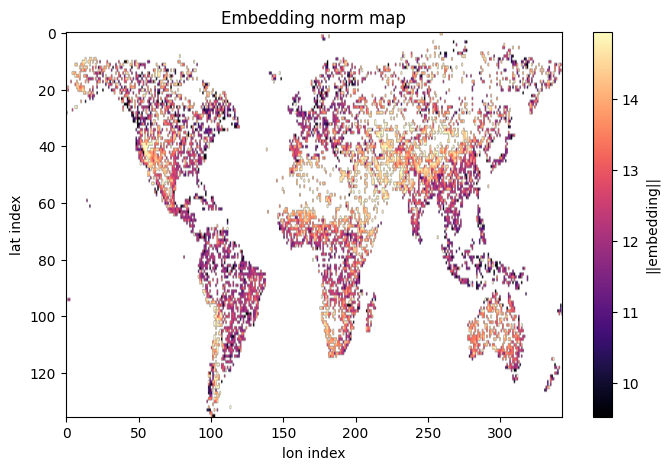

In [6]:
# TODO: experiment with whitening (PCA + unit variance scaling) as alternative normalization

norm_map = np.linalg.norm(E, axis=-1)
valid = np.isfinite(norm_map) & (norm_map > 0)

E_norm = np.full_like(E, np.nan, dtype=np.float32)
E_norm[valid] = E[valid] / norm_map[valid, None]

np.save(CACHE_DIR / "E_norm.npy", E_norm)
np.save(CACHE_DIR / "norm_map.npy", norm_map)
np.save(CACHE_DIR / "lats.npy", lats)
np.save(CACHE_DIR / "lons.npy", lons)

p_lo, p_hi = np.nanpercentile(norm_map, NORM_PERCENTILE_CLIP)
fig, ax = plt.subplots(figsize=(8, 5))
hm = ax.imshow(norm_map, cmap="magma", origin="upper", aspect="auto", vmin=p_lo, vmax=p_hi)
ax.set_title("Embedding norm map")
ax.set_xlabel("lon index")
ax.set_ylabel("lat index")
plt.colorbar(hm, ax=ax, label="||embedding||")
plt.show()

## 4. Vector-Valued Sobel Gradient

In [7]:
# TODO: implement multi-scale version — convolve Gaussian-blurred E at σ=1,2,4 and take max across scales

if KERNEL not in {"sobel", "scharr"}:
    raise ValueError("KERNEL must be 'sobel' or 'scharr'")

if KERNEL == "sobel":
    kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
    ky = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)
else:
    kx = np.array([[-3, 0, 3], [-10, 0, 10], [-3, 0, 3]], dtype=np.float32)
    ky = np.array([[-3, -10, -3], [0, 0, 0], [3, 10, 3]], dtype=np.float32)

valid_center = np.all(np.isfinite(E_norm), axis=-1)
valid_neighborhood = binary_erosion(valid_center, structure=np.ones((3, 3), dtype=bool), border_value=0)

H, W, d = E_norm.shape
Gx = np.full((H, W, d), np.nan, dtype=np.float32)
Gy = np.full((H, W, d), np.nan, dtype=np.float32)

for k in tqdm(range(d), desc=f"Applying {KERNEL} kernels"):
    sl = E_norm[:, :, k]
    filled = np.nan_to_num(sl, nan=0.0)

    gx_k = convolve(filled, kx, mode="nearest")
    gy_k = convolve(filled, ky, mode="nearest")

    gx_k[~valid_neighborhood] = np.nan
    gy_k[~valid_neighborhood] = np.nan

    # Explicit NaN borders (never force zeros at edges)
    gx_k[[0, -1], :] = np.nan
    gx_k[:, [0, -1]] = np.nan
    gy_k[[0, -1], :] = np.nan
    gy_k[:, [0, -1]] = np.nan

    Gx[:, :, k] = gx_k
    Gy[:, :, k] = gy_k

Gx_norm = np.sqrt(np.nansum(Gx**2, axis=-1))
Gy_norm = np.sqrt(np.nansum(Gy**2, axis=-1))
M = np.sqrt(Gx_norm**2 + Gy_norm**2)
theta = np.degrees(np.arctan2(Gy_norm, Gx_norm))

invalid = ~valid_neighborhood
invalid[[0, -1], :] = True
invalid[:, [0, -1]] = True
M[invalid] = np.nan
theta[invalid] = np.nan

np.save(CACHE_DIR / "M.npy", M)
np.save(CACHE_DIR / "theta.npy", theta)

print("Saved:", CACHE_DIR / "E_norm.npy", CACHE_DIR / "norm_map.npy", CACHE_DIR / "M.npy", CACHE_DIR / "theta.npy")
print("Note: For speed on large d, consider batched conv2d with torch.nn.functional.conv2d over channels.")

Applying sobel kernels:   0%|          | 0/192 [00:00<?, ?it/s]

Saved: data/cache/E_norm.npy data/cache/norm_map.npy data/cache/M.npy data/cache/theta.npy
Note: For speed on large d, consider batched conv2d with torch.nn.functional.conv2d over channels.


## 5. Latent Velocity Heatmap

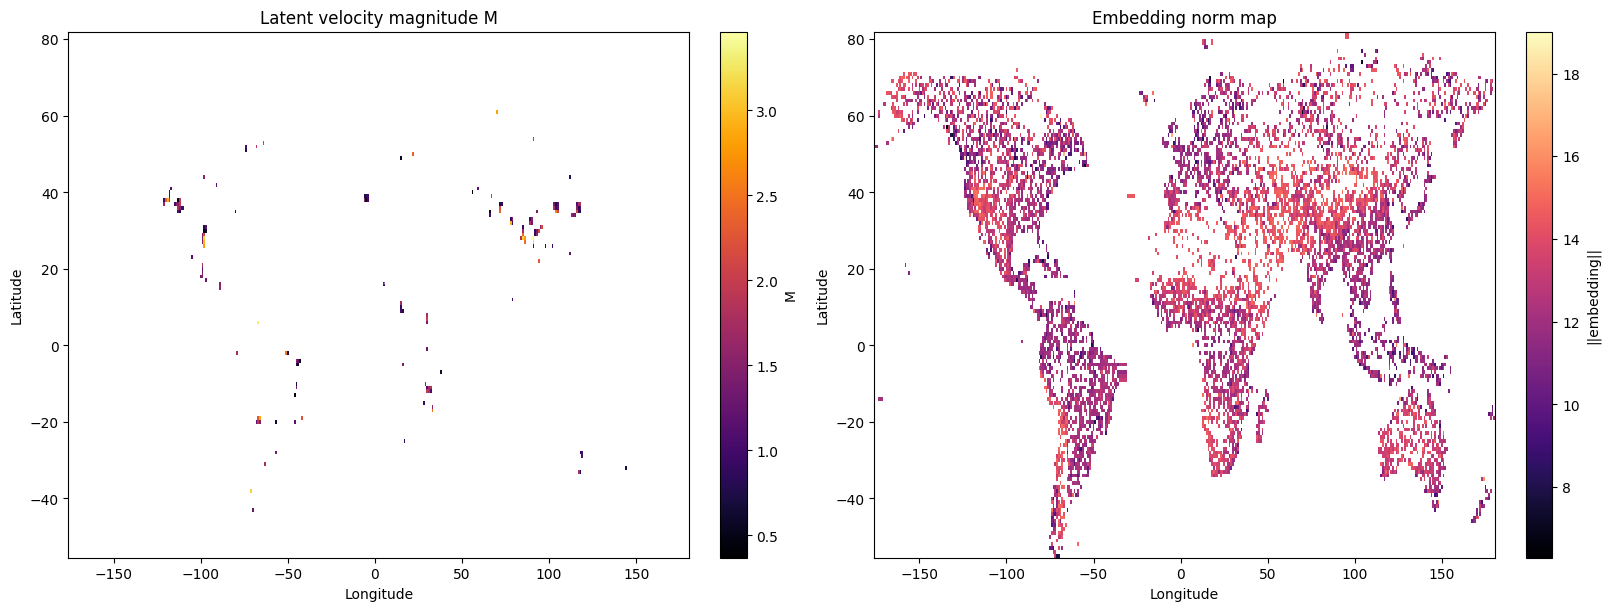

In [8]:
# TODO: add interactive version with plotly/folium, tooltip showing lat/lon/magnitude on hover

# Idempotent reload path if this cell is re-run independently
if "M" not in globals():
    M = np.load(CACHE_DIR / "M.npy")
if "theta" not in globals():
    theta = np.load(CACHE_DIR / "theta.npy")
if "norm_map" not in globals():
    norm_map = np.load(CACHE_DIR / "norm_map.npy")
if "lats" not in globals():
    lats = np.load(CACHE_DIR / "lats.npy")
if "lons" not in globals():
    lons = np.load(CACHE_DIR / "lons.npy")

lon_grid, lat_grid = np.meshgrid(lons, lats)

use_cartopy = False
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    use_cartopy = True
except Exception:
    use_cartopy = False

if use_cartopy:
    fig = plt.figure(figsize=(16, 6))
    ax0 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
    ax1 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())

    m_plot = ax0.pcolormesh(lon_grid, lat_grid, M, cmap="inferno", shading="auto", transform=ccrs.PlateCarree())
    ax0.coastlines(linewidth=0.7)
    ax0.add_feature(cfeature.BORDERS, linewidth=0.4)
    ax0.set_title("Latent velocity magnitude M")
    plt.colorbar(m_plot, ax=ax0, label="M")

    n_plot = ax1.pcolormesh(lon_grid, lat_grid, norm_map, cmap="magma", shading="auto", transform=ccrs.PlateCarree())
    ax1.coastlines(linewidth=0.7)
    ax1.add_feature(cfeature.BORDERS, linewidth=0.4)
    ax1.set_title("Embedding norm map")
    plt.colorbar(n_plot, ax=ax1, label="||embedding||")

    step = max(1, int(QUIVER_SUBSAMPLE))
    ax0.quiver(
        lon_grid[::step, ::step],
        lat_grid[::step, ::step],
        np.cos(np.deg2rad(theta[::step, ::step])),
        np.sin(np.deg2rad(theta[::step, ::step])),
        color="white",
        alpha=0.6,
        scale=35,
        width=0.002,
        transform=ccrs.PlateCarree(),
    )
else:
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

    m_plot = ax0.pcolormesh(lon_grid, lat_grid, M, cmap="inferno", shading="auto")
    ax0.set_title("Latent velocity magnitude M")
    ax0.set_xlabel("Longitude")
    ax0.set_ylabel("Latitude")
    plt.colorbar(m_plot, ax=ax0, label="M")

    n_plot = ax1.pcolormesh(lon_grid, lat_grid, norm_map, cmap="magma", shading="auto")
    ax1.set_title("Embedding norm map")
    ax1.set_xlabel("Longitude")
    ax1.set_ylabel("Latitude")
    plt.colorbar(n_plot, ax=ax1, label="||embedding||")

    step = max(1, int(QUIVER_SUBSAMPLE))
    ax0.quiver(
        lon_grid[::step, ::step],
        lat_grid[::step, ::step],
        np.cos(np.deg2rad(theta[::step, ::step])),
        np.sin(np.deg2rad(theta[::step, ::step])),
        color="white",
        alpha=0.6,
        scale=35,
        width=0.002,
    )

plt.show()

## 6. PCA RGB — What Is Changing

In [ ]:
# TODO: try UMAP(n_components=3) instead of PCA for non-linear false-color; much slower but may reveal finer structure

if "E_norm" not in globals():
    E_norm = np.load(CACHE_DIR / "E_norm.npy")
if "M" not in globals():
    M = np.load(CACHE_DIR / "M.npy")
if "lats" not in globals():
    lats = np.load(CACHE_DIR / "lats.npy")
if "lons" not in globals():
    lons = np.load(CACHE_DIR / "lons.npy")

H, W, d = E_norm.shape
valid = np.all(np.isfinite(E_norm), axis=-1)
X = E_norm[valid]

pca = PCA(n_components=PCA_COMPONENTS)
X_pca = pca.fit_transform(X)

rgb = np.full((H, W, PCA_COMPONENTS), np.nan, dtype=np.float32)
rgb[valid] = X_pca

rgb_norm = rgb.copy()
for c in range(PCA_COMPONENTS):
    ch = rgb[:, :, c]
    lo = np.nanmin(ch)
    hi = np.nanmax(ch)
    if np.isfinite(lo) and np.isfinite(hi) and hi > lo:
        rgb_norm[:, :, c] = (ch - lo) / (hi - lo)

# Fill NaNs with 0 for display only
rgb_display = np.nan_to_num(rgb_norm[:, :, :3], nan=0.0)

lon_grid, lat_grid = np.meshgrid(lons, lats)
extent = [float(lons.min()), float(lons.max()), float(lats.min()), float(lats.max())]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

hm = ax0.pcolormesh(lon_grid, lat_grid, M, cmap="inferno", shading="auto")
ax0.set_title("Where: Sobel/Scharr magnitude")
ax0.set_xlabel("Longitude")
ax0.set_ylabel("Latitude")
plt.colorbar(hm, ax=ax0, label="M")

ax1.imshow(rgb_display, extent=extent, origin="upper", aspect="auto")
ax1.set_title("What: PCA RGB of latent space")
ax1.set_xlabel("Longitude")
ax1.set_ylabel("Latitude")

plt.show()